<img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 18

### Martin van der Schelling | <a href = "mailto: m.p.vanderschelling@tudelft.nl">m.p.vanderschelling@tudelft.nl</a>  | Doctoral Candidate

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

### Elvis Aguero | <a href = "mailto: elvis_vera@brown.edu">elvis_vera@brown.edu</a>  | PhD candidate

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load jupyter notebook (it will open in your internet browser):
```
jupyter notebook
```
5. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

In [1]:
import warnings; warnings.filterwarnings("ignore") # keeps the output of the notebook clean
# Basic plotting tools needed in Python.

import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides

# To limit the number of rows to show in a dataframe, for presentation purposes:
import pandas as pd

pd.set_option('display.max_rows', 10)

SEED = 1987 # set a random seed so that everyone gets the same result
np.random.seed(SEED)

## Outline for today

* Introducing a Python framework for data-driven design and analysis of structures and materials: `f3dasm`
* Using `f3dasm` and its in-built Design of Experiments functionalities
* Simple model selection
* Advanced usage of the `f3dasm.datageneration` submodule using the `DataGenerator`
* Using the built-in features of `f3dasm`: samplers and benchmark functions
* Basic usage of optimization

**Reading material**: This notebook + `f3dasm` documentation page ([link](https://f3dasm.readthedocs.io/en/latest/))

### Installing `f3dasm`

You can install `f3dasm` with pip:

_Make sure you install the correct version (2.4.0)_

You can check this by running:

```
python -m pip list
```

In [2]:
try:
    import f3dasm
except ModuleNotFoundError: # If f3dasm is not found in current environment, install the correct version from pip
    %pip install 'f3dasm[scipy]==2.4.0' --quiet
    import f3dasm

Optionally, it is also possible to install from source:

```
git clone https://github.com/bessagroup/f3dasm
pip install -e .
```

For more installation instruction you can check the [installation documentation](https://github.com/bessagroup/f3dasm)

### `f3dasm`: streamlining your data-driven process!

The **f**ramework for **d**ata-**d**riven **d**esign and **a**nalysis of **s**tructures and **m**aterials (`f3dasm`) aims to generalize this workflow with interfaces (templates of code that you have to fill in)


<center><img src="../figures/f3dasm_carstoppingdistance_line.svg" title="f3dasm Car stopping distance" width="70%"></center>

Today, we will illustrate these modules by recreating the car stopping distance problem:

### The car stopping distance problem (again!)

<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="50%" align="right">

Imagine we want to predict $\color{red}y$ for a given ${\color{green}x}$ but that **we had no idea** that this problem is governed by:

${\color{red}y} = {\color{blue}z} x + 0.1 {\color{green}x}^2$

- ${\color{red}y}$ is the **output**: the car stopping distance
- ${\color{green}x}$ is the **input**: the car velocity
- ${\color{blue}z}$ is a hidden variable: an <a title="random variable">rv</a> $z$ representing the driver's reaction time (in seconds)

where $z \sim \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$

#### FAQ

**Does `f3dasm` contain fancy machine learning models and simulation software?**

- No, there are many other packages providing you the tools to create machine learning models (jax, pytorch, scikit-learn etc.) or material simulators (ABAQUS, Fenics)
- But you can wrap those models in `f3dasm` objects!

**But what comes in the box then?**

- `f3dasm` facilitates common interfaces where you need to provide the implementation for it!
- Think about it as a template where you need to fill in the blanks

**What is the advantage of using `f3dasm`?**

By wrapping your code into this common interface, you:
- Don't waste time implementing common data-driven procedures (e.g. data management and parallelization); this is done for you
- Allow other `f3dasm` users to use your model right away, since you have the same interfaces!
- Abide by FAIR principles (**F**indable, **A**ccessible, **I**nteroperable and **R**eusable)

<center><img src="../figures/f3dasm_overview.svg" title="f3dasm overview" width="30%"></center>

### Module `design`: Creating our design-of-experiments with the `Domain` class

<img src="../figures/f3dasm_carstopping_design.svg" title="f3dasm Car stopping distance design" width="22%" align="right">

The design-of-experiment aims to describe the variability on the **input** in order to control the **output** of the experiment.

In order to create a design-of-experiment, we import the `Domain` class from the `f3dasm.design` module:

In [3]:
from f3dasm.design import Domain

domain = Domain()
print(domain)

Domain(
  Input Space: {  }
  Output Space: {  }
)


Currently the domain is empty; but we can add the car velocity $x$ as an **input parameter**. <br>
Since it is a continuous variable, we use the `add_float` method.

Optionally, we can give lower and upper bounds to this variable:

In [4]:
domain.add_float(name='x', low=3.0, high=83.0)
print(domain)

Domain(
  Input Space: { x: ContinuousParameter(lower_bound=3.0, upper_bound=83.0, log=False) }
  Output Space: {  }
)


Let's create the **input data** for our problem...

In [5]:
N = 33 # number of points to generate data
Data_x = np.linspace(3, 83, N) # generate a dataset with N points for velocities x between 3 and 83 m/s
print("Let's see the Data_x vector:\n", Data_x)

Let's see the Data_x vector:
 [ 3.   5.5  8.  10.5 13.  15.5 18.  20.5 23.  25.5 28.  30.5 33.  35.5
 38.  40.5 43.  45.5 48.  50.5 53.  55.5 58.  60.5 63.  65.5 68.  70.5
 73.  75.5 78.  80.5 83. ]


We combine both the **domain** and the **input data** in the `f3dasm.ExperimentData` object:

In [6]:
from f3dasm import ExperimentData

experimentdata = ExperimentData(input_data=Data_x, domain=domain)
experimentdata

,jobs,input
,,x
0,open,3.0
1,open,5.5
2,open,8.0
3,open,10.5
4,open,13.0
...,...,...
28,open,73.0
29,open,75.5
30,open,78.0


This object is the central piece of the data-driven process with `f3dasm`!

Every experiment has a **job status**: `open` (not evaluated yet) or `finished`. A data generator evaluates only the `open` experiments.

### Module `datageneration`: Measure the car stopping distance

<!-- <img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="25%" align="right"> -->

<img src="../figures/f3dasm_carstopping_datageneration.svg" title="f3dasm Car stopping distance datageneration" width="22%" align="right">

We can *create* the data from the governing equation.

${\color{red}y} = {\color{blue}z} x + 0.1 {\color{green}x}^2$

- ${\color{red}y}$ is the **output**: the car stopping distance
- ${\color{green}x}$ is the **input**: the car velocity
- ${\color{blue}z}$ is a hidden variable: an <a title="random variable">rv</a> $z$ representing the driver's reaction time (in seconds)

where $z \sim \mathcal{N}(\mu_z=1.5,\sigma_z^2=0.5^2)$

We create the function `compute_distance` with the governing equation:

In [7]:
from f3dasm import datagenerator
from scipy.stats import norm # import the normal dist, as we learned before!

# Define our car stopping distance function
# We add the @datagenerator decorator to turn this function into a Data Generator block
@datagenerator(output_names=['y'])
def compute_distance(x: float) -> float:
    z = norm.rvs(1.5, 0.5, size=1) # randomly draw 1 sample from the normal dist.
    y = z*x + 0.1*x**2 # compute the stopping distance
    return float(y.item()) # return a single float value instead of an array

<img src="../figures/car_stoppingdistance.svg" title="Car stopping distance" width="40%" align="right">

We can evaluate our input data points $x$ to retrieve the stopping distance $y$:

In [8]:
experimentdata = compute_distance.call(experimentdata)
experimentdata

,jobs,input,output
,,x,y
0,finished,3.0,6.925747
1,finished,5.5,13.778612
2,finished,8.0,15.765730
3,finished,10.5,26.369206
4,finished,13.0,31.936997
...,...,...,...
28,finished,73.0,605.543426
29,finished,75.5,724.328710
30,finished,78.0,715.538528


We can extract the car stopping distance $y$ as a numpy array:

In [9]:
# to_numpy extracts both the input and output data as numpy arrays:
_, Data_y = experimentdata.to_numpy()

Text(0.5, 0, 'car velocity ($x$) [m/s]')

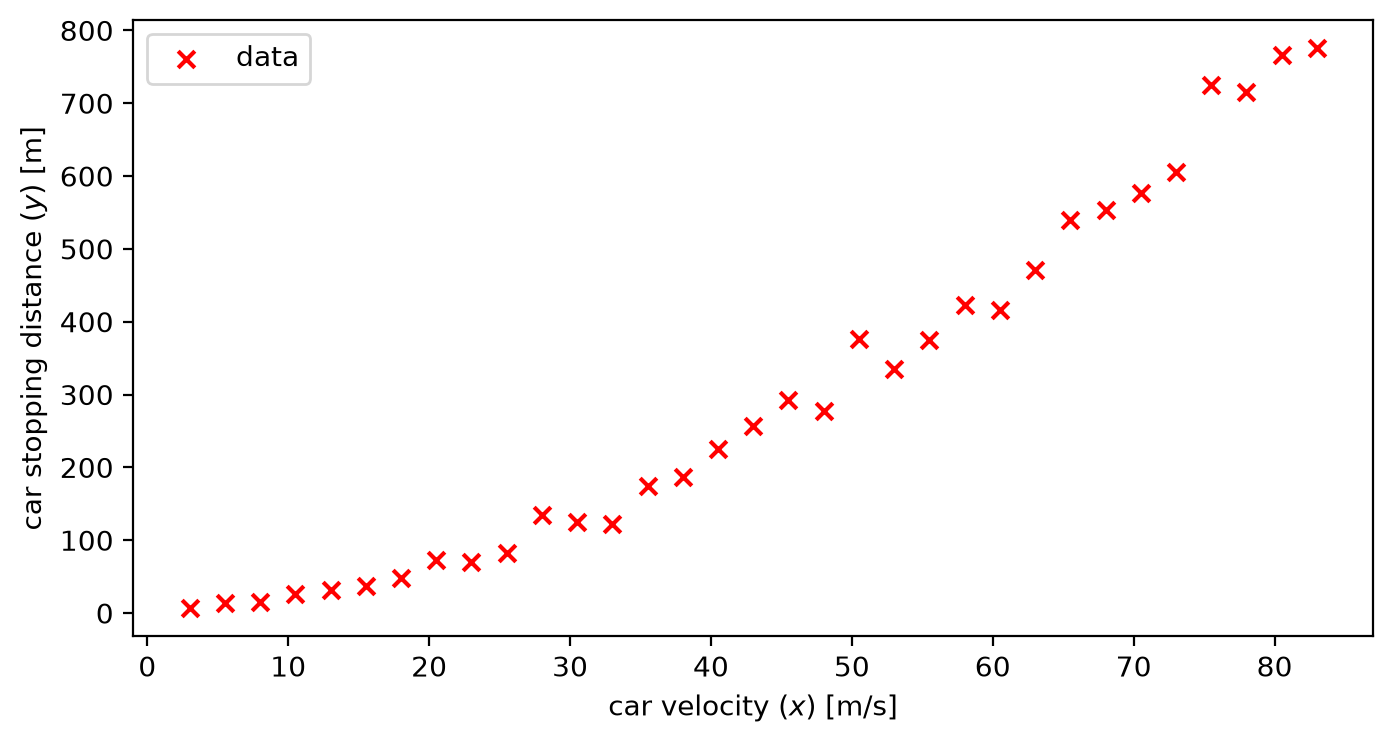

In [10]:
fig, ax = plt.subplots()
ax.scatter(Data_x, Data_y, color='r', marker='x', label='data')
ax.legend()
ax.set_ylabel('car stopping distance ($y$) [m]')
ax.set_xlabel('car velocity ($x$) [m/s]')

### Module `machine learning`: Fit a polynomial model to the data!

<img src="../figures/f3dasm_carstopping_machinelearning.svg" title="f3dasm Car stopping distance machine learning" width="22%" align="right">

Creating the polynomial model:

In [11]:
from sklearn.preprocessing import PolynomialFeatures # For Polynomial fit
from sklearn.linear_model import LinearRegression # For Least Squares
from sklearn.pipeline import make_pipeline # to link different objects

degree = 1
poly_model = make_pipeline(PolynomialFeatures(degree), LinearRegression())

Fitting the model with the data:

In [12]:
poly_model.fit(Data_x.reshape(-1, 1), Data_y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",1
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
Name,Type,Value


Now, instead of using the governing equation (`compute_distance`), we can use the model to predict the car stopping distance:

In [13]:
@datagenerator(output_names=['y_pred'])
def compute_distance_with_model(x):
    y_pred = poly_model.predict(np.array(x).reshape(-1, 1)) # We need to reshape the array
    return float(y_pred.item())

In [14]:
experimentdata = experimentdata.mark_all('open') # Mark all experiments 'open' to evaluate them again
experimentdata = compute_distance_with_model.call(experimentdata)
experimentdata

jobs input      output            
                 x           y      y_pred
0   finished   3.0    6.925747 -101.240686
1   finished   5.5   13.778612  -76.252381
2   finished   8.0   15.765730  -51.264077
3   finished  10.5   26.369206  -26.275772
4   finished  13.0   31.936997   -1.287467
..       ...   ...         ...         ...
28  finished  73.0  605.543426  598.431847
29  finished  75.5  724.328710  623.420151
30  finished  78.0  715.538528  648.408456
31  finished  80.5  766.081530  673.396761
32  finished  83.0  775.793762  698.385066

[33 rows x 4 columns]

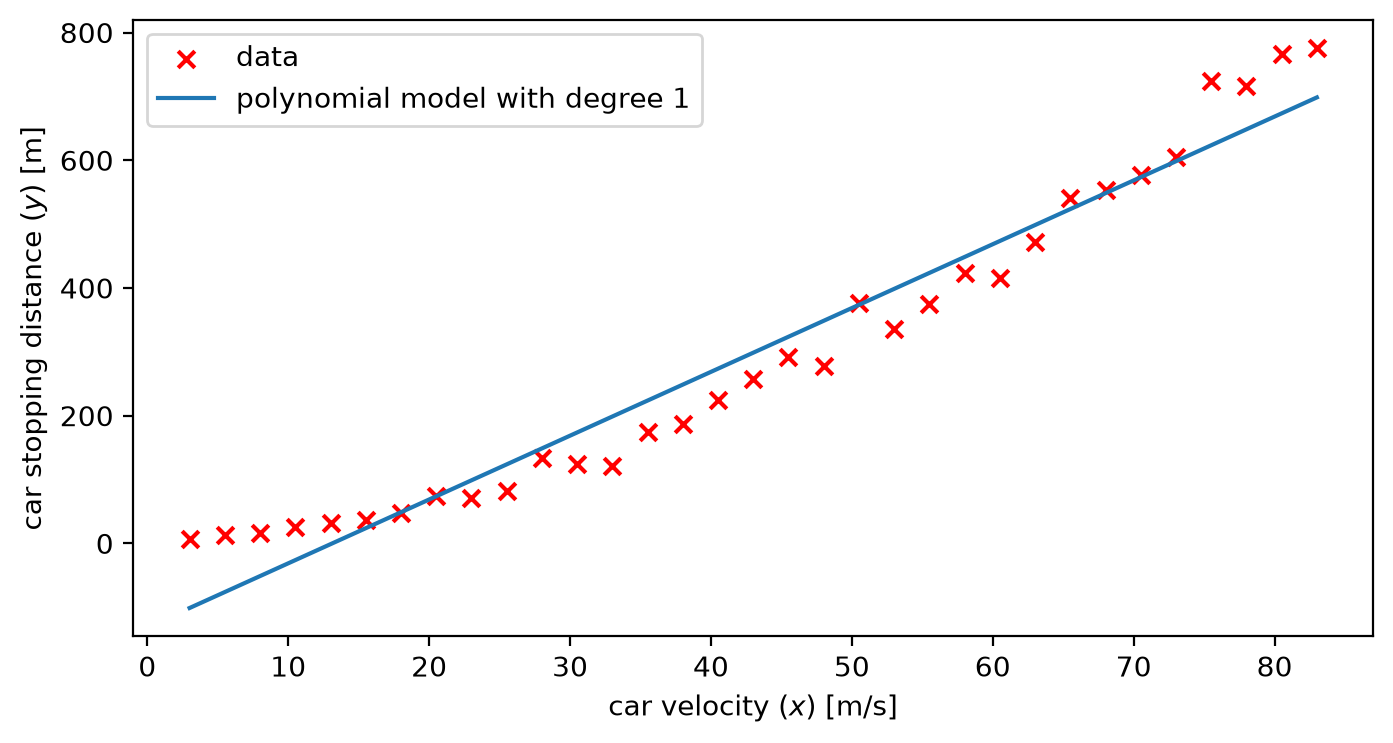

In [15]:
# Converting the ExperimentData object to numpy arrays for plotting
_, out_data = experimentdata.to_numpy()

# Plotting the data and the model prediction
fig, ax = plt.subplots()

ax.scatter(Data_x, Data_y, marker='x', color='red', label='data')
ax.plot(Data_x, out_data[:, 1], label=f'polynomial model with degree {degree}')
ax.legend()
ax.set_ylabel('car stopping distance ($y$) [m]')
ax.set_xlabel('car velocity ($x$) [m/s]')
plt.show()

## Saving the `ExperimentData`

Saving the `ExperimentData` object to your computer is easy with the `store` method:

In [16]:
experimentdata.store('./your_data')

This will create an `experiment_data` folder in the `Lecture18/your_data` directory:

```
your_data/
└── experiment_data/
     ├── domain.json
     ├── input.csv
     ├── output.csv
     └── jobs.csv    
```

Loading the `ExperimentData` from a folder is done like this:

In [17]:
ExperimentData.from_file('./your_data')

jobs input      output            
                 x           y      y_pred
0   finished   3.0    6.925747 -101.240686
1   finished   5.5   13.778612  -76.252381
2   finished   8.0   15.765730  -51.264077
3   finished  10.5   26.369206  -26.275772
4   finished  13.0   31.936997   -1.287467
..       ...   ...         ...         ...
28  finished  73.0  605.543426  598.431847
29  finished  75.5  724.328710  623.420151
30  finished  78.0  715.538528  648.408456
31  finished  80.5  766.081530  673.396761
32  finished  83.0  775.793762  698.385066

[33 rows x 4 columns]

#### Built-in sampling

We create a sampler and `call` it on our `ExperimentData` object to add datapoints to it:

Samplers, data generators and optimizers are all `Block`s of `f3dasm`, and each one is used in the same way, with `call(data=...)`.

In [18]:
from f3dasm import create_sampler

sampler = create_sampler('random_sampler', seed=SEED) # create the sampler: random uniform sampling
random_experimentdata = sampler.call(data=ExperimentData(domain=domain), n_samples=33) # draw 33 car velocities
random_experimentdata

,jobs,input
,,x
0,open,24.390474
1,open,54.585437
2,open,29.602423
3,open,43.876780
4,open,76.223990
...,...,...
28,open,6.201900
29,open,5.534940
30,open,21.001738


`f3dasm` comes with four [built-in samplers](https://f3dasm.readthedocs.io/en/latest/defaults/#implemented-samplers):
- `random_sampler`: Random uniform sampling
- `latin_sampler`: Latin Hypercube sampling
- `sobol_sampler`: Sobol sequence sampling
- `grid_sampler`: Grid search sampling

In [19]:
# We can make an array parameter like this (one variable 'x', which is an array with two elements):
domain_2d = Domain()
domain_2d.add_array(name='x', shape=(2,), low=-10., high=10.)

In [20]:
# @title Figure code: the three samplers on a 2-dimensional domain (optional)
def plot_samplers(domain_2d, n_samples=200):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    for ax, sampler_name in zip(axes.flatten(), ['random_sampler', 'latin_sampler', 'sobol_sampler']):
        sampler = create_sampler(sampler_name, seed=123)
        edata = sampler.call(data=ExperimentData(domain=domain_2d), n_samples=n_samples)
        for _, es in edata:
            ax.scatter(*es.get('x'), s=1, color='blue')
        ax.set_title(sampler_name)
    plt.show()

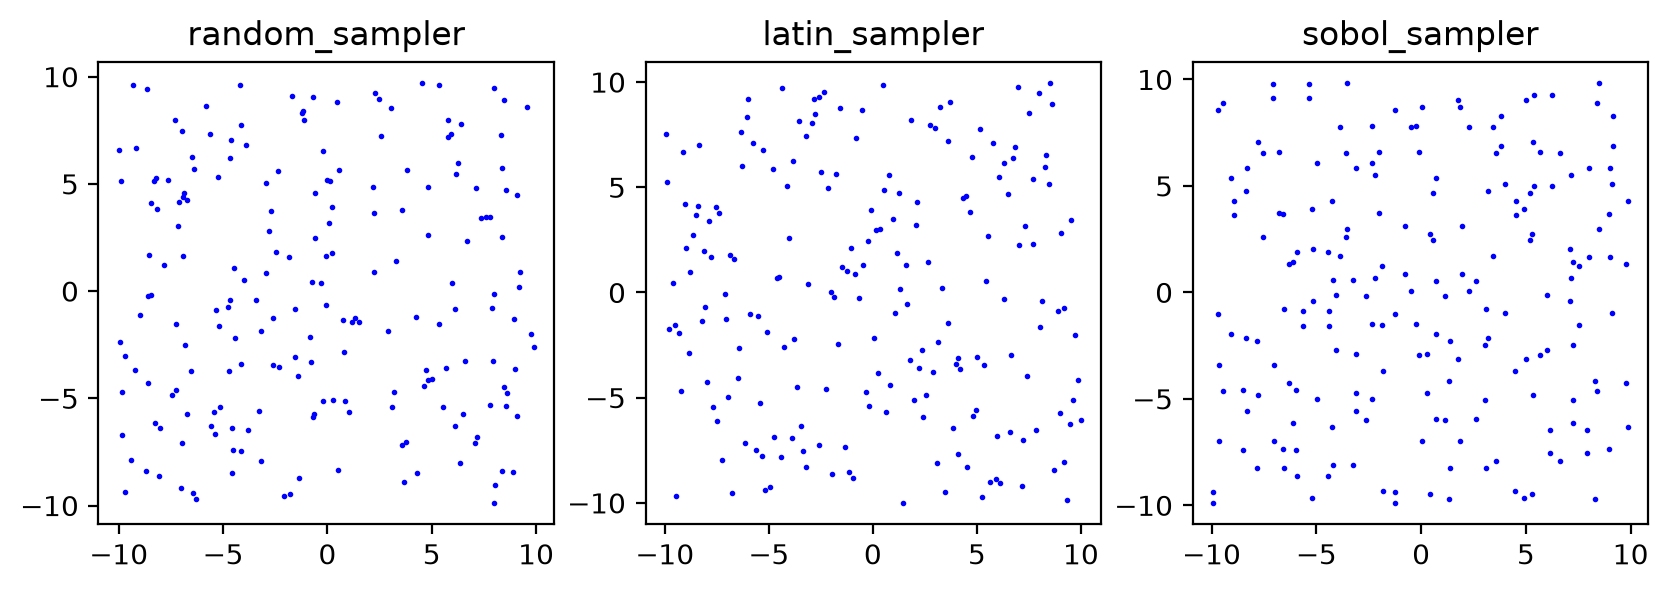

In [21]:
plot_samplers(domain_2d)

## In-class Exercise 1

`f3dasm` has some in-built sampling methods: see [built-in functionalities documentation](https://f3dasm.readthedocs.io/en/latest/defaults/#implemented-samplers)

Redo the above Design of Experiments for the car stopping distance problem but now considering $N=15$ input samples and using a different sampling method:

1. Latin Hypercube Sampling

2. Sobol Sequence sampling

In the homeworks you will explain what are the differences between these sampling methods...

In [22]:
# Write your code for Exercise 1:

# until here.

### Example: Finding polynomial degree for linear regression model with polynomial features

Let's use `f3dasm` to train a Linear Regression model with polynomials of various degrees. While you've done a similar exercise before, you'll find that `f3dasm` simplifies the workflow.

Before we start, let's think about what is our goal?

- Our goal is not just to train one model on a particular dataset. Now we want to train multiple linear regression models with different polynomial degrees.

    * Let's say that we want to compare 5 linear regression models with polynomial features of degree 1, 3, 5, 7 and 11 (like you did in a previous homework!).
    * In order for us to do that we need to evaluate the performance of each model for a particular problem. Let's pick noisy observations of the function $x \sin{x}$, i.e. $y = x \sin{x} + \epsilon$ with $\epsilon \sim \mathcal{N}(0, 0.5^2)$, on a dataset of 50 points with $x \in [0, 10]$. We will use two regression metrics to assess the performance of each model: $R^2$ and MSE scores.

1. Design of Experiments

In this case, we have 5 samples and we have **already defined them manually**: each sample is a linear regression model with polynomial features of a chosen degree!

* Therefore, we will not need to use a Sampling Method. Each sample is simply the degree of the polynomial: 1, 3, 5, 7 and 11.

2. Data generation

In this case, our goal is to **evaluate the performance** of each model. So, our output data is the $R^2$ score as well as the MSE score of each chosen model on a **validation** set.

Since we do not care about the actual regression models themselves, as we simply want to compare them, our data generation module needs to accept the polynomial degree as input, and then output the validation $R^2$ and MSE scores for that model.

In [23]:
def f(x):
    return x * np.sin(x)

sigma_noise = 0.5 # standard deviation of the Gaussian noise
rng = np.random.default_rng(SEED) # random number generator (seeded for reproducibility)

x_sin = np.linspace(0., 10., 50) # Create 50 sampling points within the bounds of 0 and 10
y_sin = f(x_sin) + rng.normal(0., sigma_noise, size=x_sin.shape) # noisy observations of f(x)=x*sin(x)

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# Split into training and testing data:
X_trainval, X_test, y_trainval, y_test = train_test_split(x_sin.reshape(-1, 1), y_sin, random_state=SEED)
# The test set is kept aside. We split the training data again, into training and validation data:
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, random_state=SEED)

### Vary the degree of the polynomial

In order to investigate the influence of the degree of the polynomial features, we are going to create a function that accepts the degree as an input, trains the model and returns the performance metrics that we are interested in.

**But careful**: if we choose the degree with the best score on the **test** set, then the test set was used to select the model, and its score is no longer an honest estimate of how the chosen model performs on new data (Lecture 17). So we split the training data again into a **training** set and a **validation** set:

* the validation scores are used to **choose** the degree;
* the test set is used only **once**, at the end, to evaluate the chosen model.

In [25]:
#___________________________________________________________________________
# 1. Design of Experiment (this time it is a manual process):
domain_degree = Domain()
domain_degree.add_int(name='poly_degree', low=0, high=20) # the lower and upper bounds do not matter
# Design the Experiment for degrees 1, 3, 5, 7 and 11:
LR_experiment_data = ExperimentData(input_data=np.array([1, 3, 5, 7, 11]), domain=domain_degree)
LR_experiment_data # show the experiments: the 5 degrees

,jobs,input
,,poly_degree
0,open,1
1,open,3
2,open,5
3,open,7
4,open,11


In [26]:
@datagenerator(output_names=['R2_val', 'MSE_val'])
def evaluate_LR_model_for_degree(poly_degree: int): # input to Data Generator is poly_degree
    # Linear regression model with polynomial features of degree poly_degree
    # (we do not scale the data here, for conciseness):
    model = make_pipeline(PolynomialFeatures(degree=poly_degree), LinearRegression())
    model.fit(X_train, y_train) # fit the training data
    y_pred = model.predict(X_val) # predict the validation data
    return r2_score(y_val, y_pred), mean_squared_error(y_val, y_pred) # output: the validation R2 and MSE scores

In [27]:
# Run Data Generator function for all input data points:
LR_experiment_data = evaluate_LR_model_for_degree.call(data=LR_experiment_data)
LR_experiment_data # the outcome of our data-driven process

jobs       input     output          
            poly_degree    MSE_val    R2_val
0  finished           1  17.300066 -0.179120
1  finished           3  17.419559 -0.187264
2  finished           5   8.662663  0.409579
3  finished           7   4.542811  0.690376
4  finished          11  33.996597 -1.317105

That's it! You only need the two code cells that define the Design of Experiments and the Data Generator to assess different models.

In this case, the best model according to the **validation** scores is the one with polynomial basis functions of degree 7 (degree 11 already overfits the noise).

Only now do we use the test set, once, to evaluate the chosen model (retrained on all the training data, i.e. training + validation):

In [28]:
# Choose the degree with the lowest validation MSE:
LR_input, LR_output = LR_experiment_data.to_pandas()
best_degree = int(LR_input['poly_degree'][LR_output['MSE_val'].idxmin()])

# Retrain the chosen model on all the training data (training + validation) and evaluate it ONCE on the test set:
best_model = make_pipeline(PolynomialFeatures(degree=best_degree), LinearRegression())
best_model.fit(X_trainval, y_trainval)
y_test_pred = best_model.predict(X_test)

print(f"Chosen degree: {best_degree}")
print(f"Test R^2 score: {r2_score(y_test, y_test_pred):.2f}")
print(f"Test MSE: {mean_squared_error(y_test, y_test_pred):.2f}")

Chosen degree: 7
Test R^2 score: 0.91
Test MSE: 1.27


#### A more general way to create a `DataGenerator` class

So far we implemented the Data Generation module with a function and the `@datagenerator` decorator.

However, there's an even more abstract (and general) way to do it...

We can create a custom class that has custom attributes and methods to allow more flexibility over the data generation process. 

I will show you how we can create the same car stopping distance dataset but now with an **object-oriented approach**.

In order to do this, you have to create a new class that inherits from the `f3dasm.datageneration.DataGenerator` class:

In [29]:
from f3dasm.datageneration import DataGenerator

class CarStoppingDistance(DataGenerator):
    def __init__(self, mu_z: float, sigma_z: float):
        self.mu_z = mu_z
        self.sigma_z = sigma_z
            
    def execute(self, experiment_sample):
        x = experiment_sample.get('x')
        z = norm.rvs(self.mu_z, self.sigma_z, size=1)
        y = z*x + 0.1*x**2
        experiment_sample.store(name='y', object=float(y.item()))
        return experiment_sample

#### Implementing the `execute()` method

- The custom class `CarStoppingDistance` can have any methods or attributes that you want
- It requires you to implement the `execute()` method
- This method will be called for every experiment when you evaluate the `ExperimentData`.
- A single experiment is called an `ExperimentSample`

#### The `ExperimentSample` object
- Each experiment will be converted into an `ExperimentSample` object
- The `ExperimentSample` can be seen as a 'row' in the table of experiments
- It is the argument `experiment_sample` that the `execute()` method receives

In [30]:
my_experimentdata = ExperimentData(input_data=Data_x, domain=domain) # the car velocities, with all jobs open
csd = CarStoppingDistance(mu_z=1.5, sigma_z=0.5) # create an object from our class, with our chosen mu_z and sigma_z

Now we `call` the data generator on the `ExperimentData` (we don't need to provide `output_names` for the custom class approach since we decided on them in the `store` method of the `ExperimentSample`)

In [31]:
my_experimentdata = csd.call(data=my_experimentdata)
my_experimentdata # the jobs become "finished"

,jobs,input,output
,,x,y
0,finished,3.0,3.609804
1,finished,5.5,11.544626
2,finished,8.0,20.601553
3,finished,10.5,24.101980
4,finished,13.0,38.817795
...,...,...,...
28,finished,73.0,650.020356
29,finished,75.5,734.870842
30,finished,78.0,706.431582


### Easy parallelization

One common procedure that everyone encounters at some point is **parallelization**.

&#x1F31F; The `call` method of a `DataGenerator` offers three different modes of evaluating all the experiments:
- `sequential` mode: evaluates each experiment one at a time (default)
- `parallel` mode: using multiprocessing capabilities, evaluating the experiments in parallel on your cores
- `cluster` mode: after each writing operation, saves the `ExperimentData` object to disk so it can be accessed by different processes. Useful for the Brown CCV

For example: `csd.call(data=my_experimentdata, mode='parallel')`.

To keep arrays or other large objects of an experiment as files (and only a reference in the table), store them with `experiment_sample.store(name=..., object=..., to_disk=True)`.

### Built-in defaults

`f3dasm` comes with [built-in functionalities](https://f3dasm.readthedocs.io/en/latest/defaults/) for each of the stages of the data-driven process to get you started right away.

For each of the stages of the data-driven process, you can provide a string argument from the list of available options instead of a function/class object:

- **sampling**: `create_sampler('random_sampler')`
- **data generation**: `create_datagenerator('ackley')`
- **optimization**: `create_optimizer('cg', data_generator=..., input_name=..., output_name=...)`

We already used built-in sampling. Next we use built-in data generation and optimization.

#### Built-in data generation

`f3dasm` comes with a [collection of benchmark functions](https://f3dasm.readthedocs.io/en/latest/defaults/#implemented-benchmark-functions) that can used to evaluate your experiments.

For instance, the Levy function.

In [32]:
sampler = create_sampler('random_sampler', seed=123)
experiment_data = ExperimentData(domain=domain_2d)
experiment_data = sampler.call(data=experiment_data, n_samples=10) # 10 random points in the 2-dimensional domain

In [33]:
from f3dasm import create_datagenerator

data_generator = create_datagenerator('levy', output_names='y')

experiment_data = data_generator.call(data=experiment_data)
experiment_data # the new column y: the Levy function at each point

,jobs,input,output
,,x,y
0,finished,"[3.6470372649628686, -8.923579623955547]",7.461407
1,finished,"[-5.592802544547773, -6.312563786026606]",29.574500
2,finished,"[-6.481881978299393, 6.241890133115472]",40.909259
3,finished,"[8.466899960541127, -4.468512044057875]",17.052997
4,finished,"[6.395091231860043, 7.797853862223718]",21.728063
5,finished,"[0.25940910459063815, -5.1007079786240705]",2.776598
6,finished,"[6.484831921948228, -5.72474073249809]",20.770015
7,finished,"[4.829341044694193, 2.5988040917936157]",6.467240
8,finished,"[8.54814517050334, -5.361836227871624]",19.818509


### Optimization

<img src="../figures/f3dasm_optimization.svg" title="f3dasm optimization" width="22%" align="right">

Optimizers are `Block`s too, just like samplers and data generators. To create one, you provide:
- the data generator (built-in or custom) whose output should be minimized
- the names of the input and output parameter to optimize over
- the iteration budget

The `scipy` optimizers run their own internal loop, so a single `call` performs the whole optimization.

In [34]:
from f3dasm import create_optimizer

# The optimizer is wired up when you create it, and 'maxiter' is the iteration budget
optimizer = create_optimizer('lbfgsb',
                             data_generator=data_generator,
                             input_name='x',
                             output_name='y',
                             maxiter=30)

optimizer.arm(experiment_data) # take the starting point from the last experiment

# 'call' returns the data with the optimization history already appended to it
experiment_data = optimizer.call(experiment_data)
experiment_data # the starting points and the iterations of the optimizer

,jobs,input,output
,,x,y
0,finished,"[3.6470372649628686, -8.923579623955547]",7.461407e+00
1,finished,"[-5.592802544547773, -6.312563786026606]",2.957450e+01
2,finished,"[-6.481881978299393, 6.241890133115472]",4.090926e+01
3,finished,"[8.466899960541127, -4.468512044057875]",1.705300e+01
4,finished,"[6.395091231860043, 7.797853862223718]",2.172806e+01
...,...,...,...
12,finished,"[1.0000007572403402, 1.0000015255255057]",6.783768e-04
13,finished,"[1.0000007572403402, 1.0000015255255057]",3.779844e-05
14,finished,"[1.0000007572403402, 1.0000015255255057]",2.453466e-07


## Field guide: what this lecture adds

### Good practices

**1. Frame the problem**
- **Keep one record of the experiments**: the inputs described by a `Domain`, the outputs, and the status of each job (`open` or `finished`), stored to disk with `store` and read back with `from_file`.
- **Wrap your code in the `f3dasm` interfaces** (`datagenerator`, `DataGenerator`) instead of rewriting the data-driven procedure. The management of the data and the parallelization come with them.

**5. Validate and select**
- **Choose models and hyperparameters on validation data**, with cross-validation on the training set, reading the means together with their spread. Use the test set once, at the end, to report the chosen model.
- **Compare many models as one experiment**: each experiment is a model (for example the degree of a polynomial), its outputs are the errors on the validation data, and the choice is read from the record.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### Other things to explore ...

- &#x1F31F; [Hydra](https://hydra.cc/) configuration integration; separating your constants and parameters from your code!
- &#x1F31F; [Studies](https://github.com/bessagroup/f3dasm/tree/main/studies), showcasing paper replications with the `f3dasm` workflow
- &#x1F31F; [abaqus2py](https://pypi.org/project/abaqus2py/) port of managing multiple simulations of ABAQUS with `f3dasm` (under development)

### See you next class!

Useful links

- &#x1F31F; [GitHub repository](https://github.com/bessagroup/f3dasm)
- &#x1F4D5; [Online documentation](https://f3dasm.readthedocs.io/)
- &#x1F4F0; [JOSS Paper](https://doi.org/10.21105/joss.06912)

Give the repository a star &#x1F600; !